In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("uber.csv")

In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [6]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [7]:
df_clean = df.drop(columns=['Unnamed: 0', 'key', 'pickup_datetime'])
df_clean = df_clean.dropna() 

In [8]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199999 non-null  float64
 1   pickup_longitude   199999 non-null  float64
 2   pickup_latitude    199999 non-null  float64
 3   dropoff_longitude  199999 non-null  float64
 4   dropoff_latitude   199999 non-null  float64
 5   passenger_count    199999 non-null  int64  
dtypes: float64(5), int64(1)
memory usage: 10.7 MB


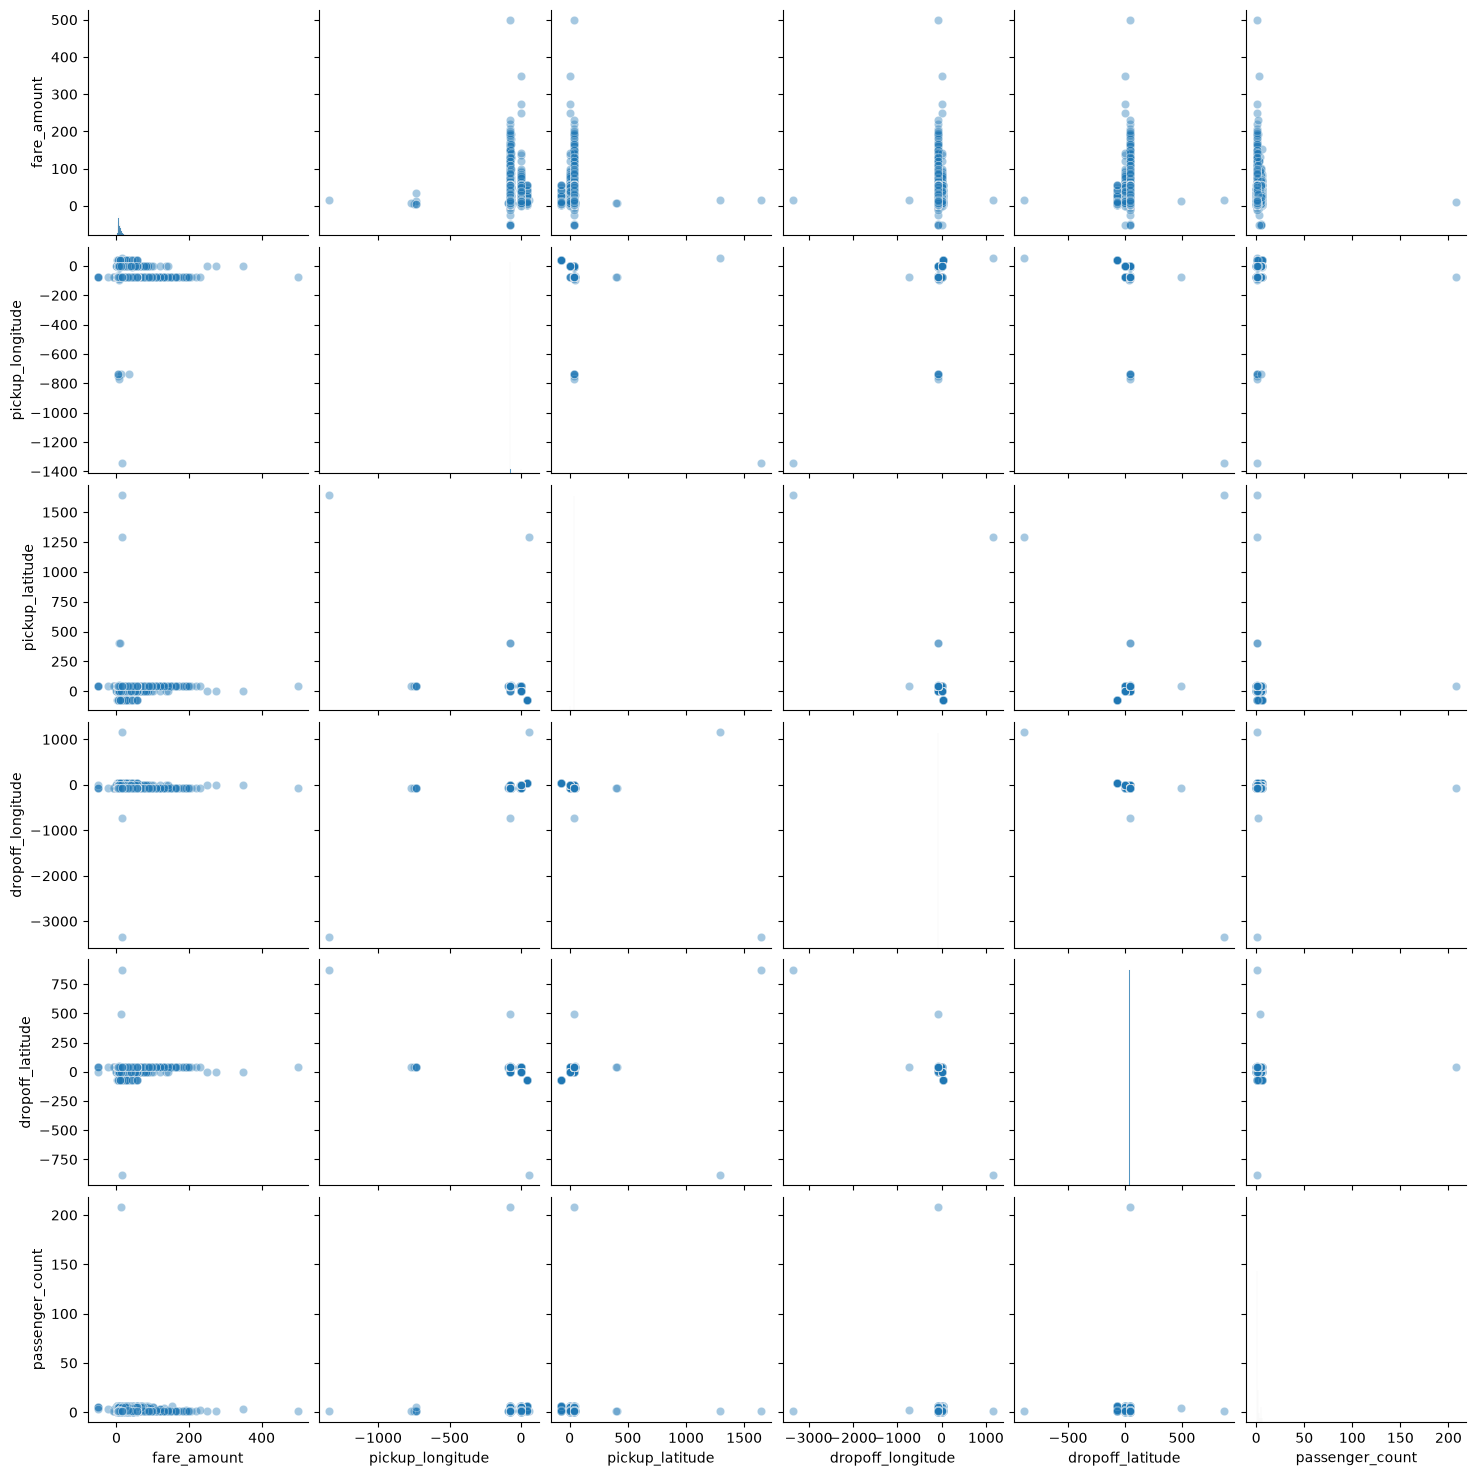

In [9]:
sns.pairplot(df_clean, kind='scatter', plot_kws={'alpha': 0.4})

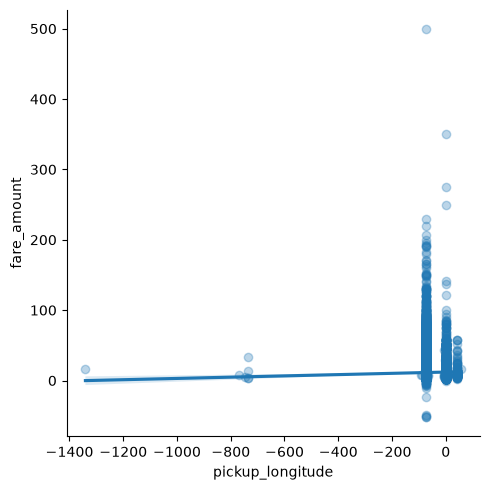

In [10]:
sns.lmplot(x = "pickup_longitude",
          y ="fare_amount",
          data = df_clean,
          scatter_kws={'alpha':0.3})

In [11]:
import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df_clean['distance_km'] = haversine(
    df_clean['pickup_latitude'],
    df_clean['pickup_longitude'],
    df_clean['dropoff_latitude'],
    df_clean['dropoff_longitude']
)

In [12]:
df_clean['distance_km'].describe()

count    199999.000000
mean         20.855350
std         382.964642
min           0.000000
25%           1.215222
50%           2.120992
75%           3.875169
max       16409.239135
Name: distance_km, dtype: float64

<Axes: xlabel='distance_km', ylabel='fare_amount'>

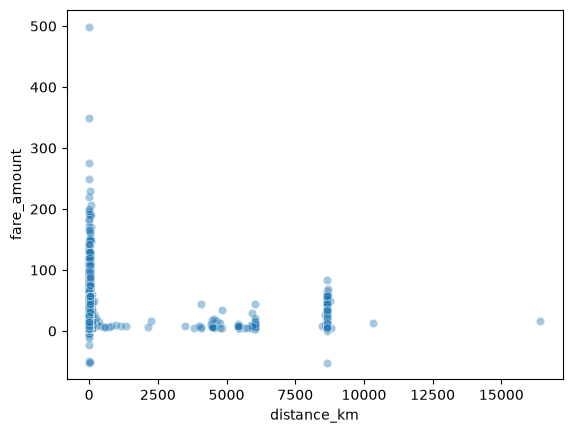

In [13]:
sns.scatterplot(data=df_clean, x='distance_km', y='fare_amount', alpha=0.4)

In [14]:
# remove missing values and duplicates
df_clean = df_clean.dropna().drop_duplicates()

# remove impossible / extreme values
df_clean = df_clean[
    df_clean['fare_amount'].between(2.5, 200) &
    df_clean['passenger_count'].between(1, 6) &
    df_clean['pickup_longitude'].between(-75, -72) &
    df_clean['dropoff_longitude'].between(-75, -72) &
    df_clean['pickup_latitude'].between(40, 42) &
    df_clean['dropoff_latitude'].between(40, 42) &
    df_clean['distance_km'].between(0.1, 100)
].reset_index(drop=True)

In [15]:
df_clean['distance_km'].describe()

count    191893.000000
mean          3.382492
std           3.728733
min           0.100227
25%           1.294832
50%           2.193120
75%           3.957398
max          99.162509
Name: distance_km, dtype: float64

<Axes: xlabel='distance_km', ylabel='fare_amount'>

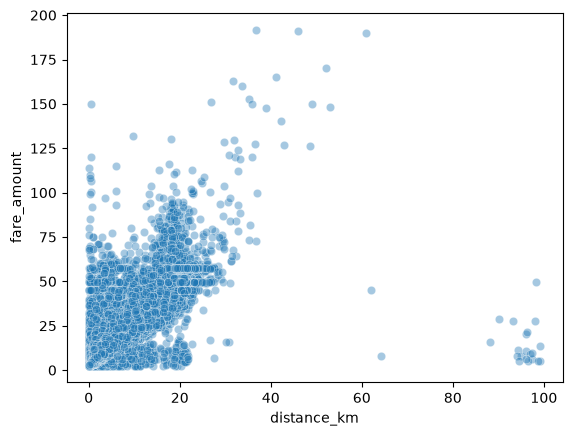

In [16]:
sns.scatterplot(data=df_clean, x='distance_km', y='fare_amount', alpha=0.4)

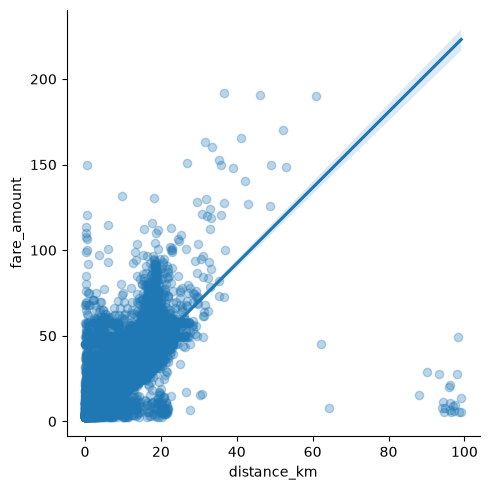

In [17]:
sns.lmplot(x = "distance_km",
          y ="fare_amount",
          data = df_clean,
          scatter_kws={'alpha':0.3})

In [18]:
from sklearn.model_selection import train_test_split

In [24]:
x = df_clean[['distance_km']]
y = df_clean['fare_amount']

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3, random_state = 42)

In [26]:
from sklearn.linear_model import LinearRegression

In [27]:
lm = LinearRegression()

In [28]:
lm.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.23]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['distance_km']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.77
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [29]:
lm.coef_


array([2.23256459])

In [31]:
cdf = pd.DataFrame(lm.coef_,x.columns, columns = ['Coef'])
print(cdf)

                 Coef
distance_km  2.232565


In [32]:
predictions = lm.predict(x_test)

In [33]:
predictions

array([ 5.99587904, 43.04470547, 19.11752222, ...,  5.06838459,
        8.45951139,  7.54679452], shape=(57568,))

Text(0.5, 1.0, 'Evaluation of our LM model')

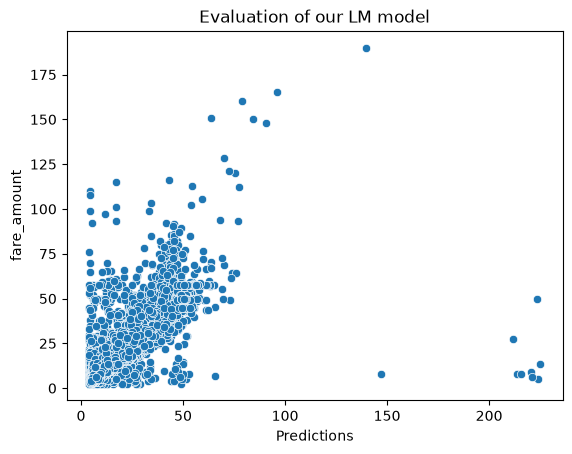

In [34]:
sns.scatterplot(x = predictions, y= y_test)
plt.xlabel('Predictions')
plt.title('Evaluation of our LM model')

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

In [36]:
print("MAE: ", mean_absolute_error(y_test, predictions))
print("MSE: ", mean_squared_error(y_test, predictions))
print("RMsE: ", math.sqrt(mean_squared_error(y_test, predictions)))

MAE:  2.322418269881155
MSE:  23.918747632749028
RMsE:  4.890679669815744


In [37]:
residuals = y_test - predictions

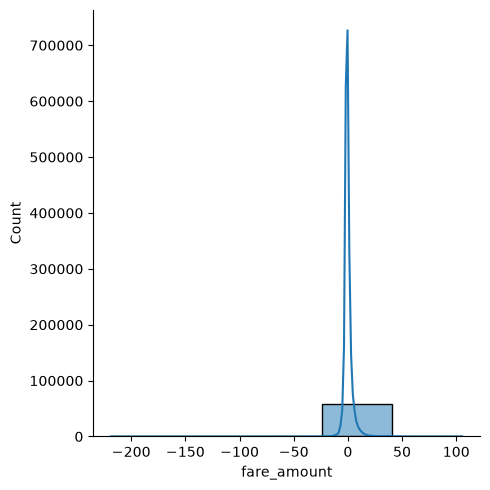

In [40]:
sns.displot(residuals, bins= 5, kde=True)

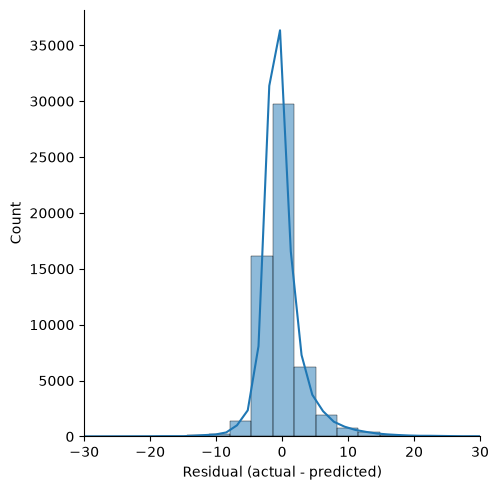

In [44]:
sns.displot(residuals, bins=100, kde=True)
plt.xlim(-30, 30)
plt.xlabel('Residual (actual - predicted)')
plt.show()

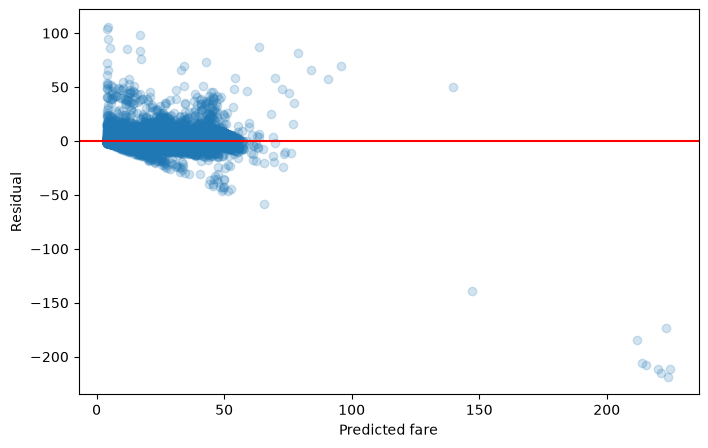

In [45]:
plt.figure(figsize=(8, 5))
plt.scatter(predictions, residuals, alpha=0.2)
plt.axhline(0, color='red')
plt.xlabel('Predicted fare')
plt.ylabel('Residual')
plt.show()